In [1]:
# !pip install pandas


In [2]:
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
dataset=pd.read_csv("Dataset .csv")
dataset.head(3)

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270


# EDA

In [4]:
dataset.shape

(9551, 21)

In [5]:
dataset.info

<bound method DataFrame.info of       Restaurant ID           Restaurant Name  Country Code              City  \
0           6317637          Le Petit Souffle           162       Makati City   
1           6304287          Izakaya Kikufuji           162       Makati City   
2           6300002    Heat - Edsa Shangri-La           162  Mandaluyong City   
3           6318506                      Ooma           162  Mandaluyong City   
4           6314302               Sambo Kojin           162  Mandaluyong City   
...             ...                       ...           ...               ...   
9546        5915730               Naml۱ Gurme           208         ��stanbul   
9547        5908749              Ceviz A��ac۱           208         ��stanbul   
9548        5915807                     Huqqa           208         ��stanbul   
9549        5916112               A���k Kahve           208         ��stanbul   
9550        5927402  Walter's Coffee Roastery           208         ��stanbul

In [6]:
dataset.describe()

,Restaurant ID,Country Code,Longitude,Latitude,Average Cost for two,Price range,Aggregate rating,Votes
count,9.551000e+03,9551.000000,9551.000000,9551.000000,9551.000000,9551.000000,9551.000000,9551.000000
mean,9.051128e+06,18.365616,64.126574,25.854381,1199.210763,1.804837,2.666370,156.909748
std,8.791521e+06,56.750546,41.467058,11.007935,16121.183073,0.905609,1.516378,430.169145
min,5.300000e+01,1.000000,-157.948486,-41.330428,0.000000,1.000000,0.000000,0.000000
25%,3.019625e+05,1.000000,77.081343,28.478713,250.000000,1.000000,2.500000,5.000000
50%,6.004089e+06,1.000000,77.191964,28.570469,400.000000,2.000000,3.200000,31.000000
75%,1.835229e+07,1.000000,77.282006,28.642758,700.000000,2.000000,3.700000,131.000000
max,1.850065e+07,216.000000,174.832089,55.976980,800000.000000,4.000000,4.900000,10934.000000


In [7]:
dataset.columns

Index(['Restaurant ID', 'Restaurant Name', 'Country Code', 'City', 'Address',
       'Locality', 'Locality Verbose', 'Longitude', 'Latitude', 'Cuisines',
       'Average Cost for two', 'Currency', 'Has Table booking',
       'Has Online delivery', 'Is delivering now', 'Switch to order menu',
       'Price range', 'Aggregate rating', 'Rating color', 'Rating text',
       'Votes'],
      dtype='str')

## convert RestaurantId  datatype to string and Country code to category

In [8]:
dataset['Restaurant ID']= dataset['Restaurant ID'].astype(str)
dataset['Country Code']= dataset['Country Code'].astype("category")

In [9]:
dataset.describe()

,Longitude,Latitude,Average Cost for two,Price range,Aggregate rating,Votes
count,9551.000000,9551.000000,9551.000000,9551.000000,9551.000000,9551.000000
mean,64.126574,25.854381,1199.210763,1.804837,2.666370,156.909748
std,41.467058,11.007935,16121.183073,0.905609,1.516378,430.169145
min,-157.948486,-41.330428,0.000000,1.000000,0.000000,0.000000
25%,77.081343,28.478713,250.000000,1.000000,2.500000,5.000000
50%,77.191964,28.570469,400.000000,2.000000,3.200000,31.000000
75%,77.282006,28.642758,700.000000,2.000000,3.700000,131.000000
max,174.832089,55.976980,800000.000000,4.000000,4.900000,10934.000000


In [10]:
dataset.describe(exclude="number")

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Cuisines,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Rating color,Rating text
count,9551,9551,9551,9551,9551,9551,9551,9542,9551,9551,9551,9551,9551,9551,9551
unique,9551,7446,15,141,8918,1208,1265,1825,12,2,2,2,1,6,6
top,6317637,Cafe Coffee Day,1,New Delhi,"Dilli Haat, INA, New Delhi",Connaught Place,"Connaught Place, New Delhi",North Indian,Indian Rupees(Rs.),No,No,No,No,Orange,Average
freq,1,83,8652,5473,11,122,122,936,8652,8393,7100,9517,9551,3737,3737


## check missing value for each col

In [11]:
dataset.isnull().sum()

Restaurant ID           0
Restaurant Name         0
Country Code            0
City                    0
Address                 0
Locality                0
Locality Verbose        0
Longitude               0
Latitude                0
Cuisines                9
Average Cost for two    0
Currency                0
Has Table booking       0
Has Online delivery     0
Is delivering now       0
Switch to order menu    0
Price range             0
Aggregate rating        0
Rating color            0
Rating text             0
Votes                   0
dtype: int64

## check duplicate value

In [12]:
dataset.duplicated().sum()

np.int64(0)

In [13]:
dataset.head(3)

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270


# TASK 1 
## Task: Top Cuisines

## Ques--Determine the top three most common cuisines in the dataset.

In [14]:
cuisines=(
    dataset['Cuisines'].dropna().str.split(",").explode().str.strip()
)
top3= cuisines.value_counts().head(3)
print(top3)

Cuisines
North Indian    3960
Chinese         2735
Fast Food       1986
Name: count, dtype: int64


## Ques-- Calculate the percentage of restaurants that serve each of the top cuisines.

In [15]:
total_rest= len(dataset)
total_rest

9551

In [16]:
percentage= (top3/total_rest *100).round(2)
percentage

Cuisines
North Indian    41.46
Chinese         28.64
Fast Food       20.79
Name: count, dtype: float64

# TASK2
## Task: City Analysis

## Ques-- Identify the city with the highest number of restaurants in the dataset.

In [17]:
dataset["City"].value_counts().idxmax()
# res=dataset["City"].value_counts()
# res

'New Delhi'

## Ques-- Calculate the average rating for restaurants in each city.

In [18]:
city_avg_rating=dataset.groupby('City')['Aggregate rating'].mean().sort_values(ascending=False).round(2)
city_avg_rating

City
Inner City          4.90
Quezon City         4.80
Makati City         4.65
Pasig City          4.63
Mandaluyong City    4.62
                    ... 
New Delhi           2.44
Montville           2.40
Mc Millan           2.40
Noida               2.04
Faridabad           1.87
Name: Aggregate rating, Length: 141, dtype: float64

## Ques-- Determine the city with the highest average rating.

In [19]:
city_avg_rating.idxmax()

'Inner City'

# TASK3
## Task: Price Range Distribution

## Ques-- Create a histogram or bar chart to visualize the distribution of price ranges among the restaurants.

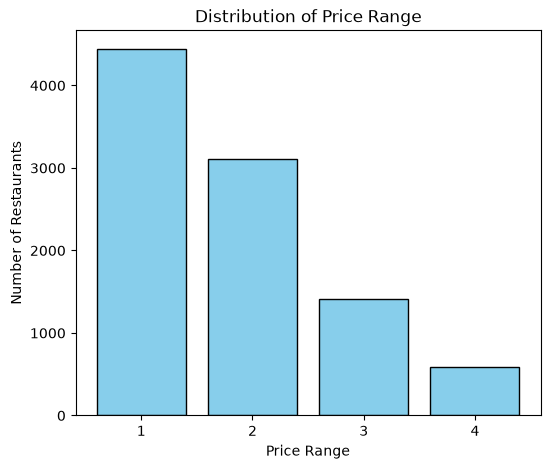

In [20]:
plt.figure(figsize=(6,5))
plt.bar(dataset["Price range"].value_counts().sort_index().index,
        dataset["Price range"].value_counts().sort_index().values,
        color="skyblue", edgecolor="black")
plt.title("Distribution of Price Range")
plt.xlabel("Price Range")
plt.ylabel("Number of Restaurants")
plt.xticks([1,2,3,4])
plt.show()

## Ques-- Calculate the percentage of restaurants in each price range category.

In [21]:
price_count= dataset['Price range'].value_counts().sort_index()
# price_count
price_percent= (price_count/len(dataset)*100).round(2)
price_percent

Price range
1    46.53
2    32.59
3    14.74
4     6.14
Name: count, dtype: float64

# TASK4
## Task: Online Delivery

## Ques-- Determine the percentage of restaurants that offer online delivery.

In [22]:
delivery_percent=(dataset['Has Table booking']=="Yes").mean()*100
delivery_percent

np.float64(12.124384881164275)

## Ques-- Compare the average ratings of restaurants with and without online delivery.

In [23]:
avg_rating_by_delivery = dataset.groupby("Has Online delivery")["Aggregate rating"].mean().round(2)
print(avg_rating_by_delivery)


Has Online delivery
No     2.47
Yes    3.25
Name: Aggregate rating, dtype: float64


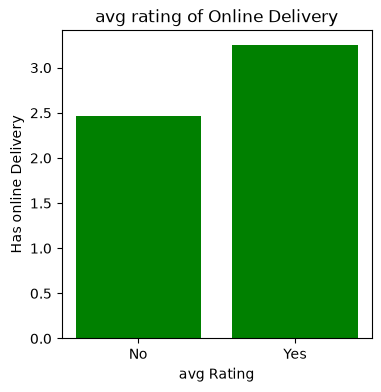

In [24]:
plt.figure(figsize=(4,4))
plt.bar(avg_rating_by_delivery.index,
       avg_rating_by_delivery.values,
       color="green")
plt.title("avg rating of Online Delivery")
plt.ylabel("Has online Delivery")
plt.xlabel("avg Rating")
plt.show()